# TopoDiffusionNet en miniature — évaluation finale

On compare trois modèles **au même budget d'entraînement (24 000 pas)**, partis du même ADM-T entraîné 15 000 pas :

| modèle | 15 000 premiers pas | 9 000 pas suivants |
|---|---|---|
| **ADM-T 24k** | L_simple | L_simple |
| **TDN λ=1e-3** | L_simple | L_simple + 1e-3·L_top (pour t < 500) |
| **TDN λ=1e-5** | L_simple | L_simple + 1e-5·L_top (pour t < 500) |

La seule différence entre eux est donc la perte topologique L_top et son poids λ. À λ = 1e-5 (valeur du premier entraînement), L_top ne pèse qu'environ 0,2 % du gradient de L_simple ; à λ = 1e-3, environ 20 %.

Les tableaux de la section 3 comparent les trois modèles ; les sections 4 à 8 détaillent **ADM-T 24k contre TDN λ=1e-3** (appelé simplement « TDN » dans les titres).

Ce notebook **n'entraîne rien** (voir `train.ipynb`) et peut être exécuté en entier (*Run All*) :
- les échantillons sont générés une seule fois puis relus depuis `samples/` ;
- **sur GPU** : 200 échantillons par valeur de c ; **sur CPU** : 50 (premier lancement : quelques minutes par modèle).

Plan : 1. modèles · 2. génération · 3. résultats · 4. matrices de confusion · 5. comparaison appariée · 6. exemples · 7. types d'erreurs · 8. x̂₀ au fil du débruitage.

## 0. Installation
Sur Colab : installe les dépendances, monte Google Drive et se place dans le dossier du projet. En local, la cellule ne fait rien.

In [1]:
import os
import sys

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    !pip install -q diffusers cripser
    drive.mount('/content/drive')
#    PROJECT_DIR = "/content/drive/MyDrive/01 Études/Master MVA/Topologie/topodiffusion-mini"
    PROJECT_DIR = "/content/drive/MyDrive/topodiffusion-mini"
    # si le code est dans un sous-dossier du même nom (comme sur le PC)
    if not os.path.exists(os.path.join(PROJECT_DIR, "data.py")):
        PROJECT_DIR = os.path.join(PROJECT_DIR, "topodiffusion-mini")
    os.chdir(PROJECT_DIR)
    sys.path.insert(0, PROJECT_DIR)  # pour `from data import ...`
print("Colab" if IN_COLAB else "local", "|", os.getcwd())

Mounted at /content/drive
Colab | /content/drive/.shortcut-targets-by-id/15vvSEg1SCSd9dq9KZqO2ElOVP_4VfwGo/topodiffusion-mini


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.ticker import PercentFormatter
from scipy import ndimage
from scipy.stats import binomtest

from config import COLORS, NUM_STEPS, REF, THRESHOLD, keep_existing, main_models, n_per_c
from data import C_VALUES
from evaluate import tables
from sample import cached_samples_all, cached_trajectories
from train import ckpt_step

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU :", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "aucun (CPU)")

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad",
    "axes.titlesize": 10,
    "font.size": 9,
})
GOOD, BAD = "#0ca30c", "#d03b3b"  # juste / faux (toujours accompagné de ✓ / ✗)
# une couleur par composante connexe, pour voir ce que compte la métrique
COMP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#e34948"]


def show_mask(ax, img, c=None, header=""):
    # Masque seuillé, une couleur par composante ; titre « ĉ = n ✓/✗ » si c est donné,
    # sous un en-tête neutre (header).
    labels, n = ndimage.label(img > THRESHOLD)
    rgb = np.ones((*labels.shape, 3))
    for k in range(1, n + 1):
        rgb[labels == k] = to_rgb(COMP_COLORS[(k - 1) % len(COMP_COLORS)])
    ax.imshow(rgb, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(True)
        side.set_color("#d9d8d2")
    if c is not None:
        mark = "✓" if n == c else "✗"
        ax.set_title(f"ĉ = {n} {mark}", fontsize=8, color=GOOD if n == c else BAD, pad=3)
    if header:
        ax.text(0.5, 1.17, header, transform=ax.transAxes, ha="center", va="bottom", fontsize=8, color="#1f1e1c")
    return n


def pct(x, signed=False):
    return f"{100 * x:+.1f} pts" if signed else f"{100 * x:.1f} %"

GPU : Tesla T4


## 1. Modèles et réglages

In [3]:
N_PER_C = n_per_c(DEVICE)  # 200 sur GPU, 50 sur CPU
FORCE_REGEN = False  # True : régénère échantillons et trajectoires même s'ils existent déjà

TDN, OLD = "TDN λ=1e-3", "TDN λ=1e-5"
MODELS = keep_existing(main_models())
assert REF in MODELS and TDN in MODELS, f"il faut {REF} et {TDN} (voir train.ipynb)"
NAMES = [REF, TDN]  # comparés en détail (sections 4 à 8)
ALL = [name for name in (REF, TDN, OLD) if name in MODELS]  # tableaux de la section 3

LAST = {REF: "L_simple", TDN: "L_simple + 1e-3·L_top", OLD: "L_simple + 1e-5·L_top"}
steps = {name: ckpt_step(MODELS[name][0]) for name in ALL}
total = {name: steps[name] + (0 if name == REF else 15_000) for name in ALL}  # TDN : pas comptés depuis ADM-T 15k
display(pd.DataFrame({
    "checkpoint": {name: MODELS[name][0] for name in ALL},
    "pas d'entraînement au total": total,
    "9 000 derniers pas": {name: LAST[name] for name in ALL},
}))
if len(set(total.values())) > 1:
    print("attention : budgets différents, la comparaison n'est pas à budget égal")
print(f"{N_PER_C} échantillons par valeur de c, sur {DEVICE}")

ADM-T 24k              : ckpt/admt_suite_24k.pt (pas 24000)
TDN λ=1e-3             : ckpt/tdn_lam1e-3_9k.pt (pas 9000)
TDN λ=1e-5             : ckpt/tdn/last.pt (pas 9000)


,checkpoint,pas d'entraînement au total,9 000 derniers pas
ADM-T 24k,ckpt/admt_suite_24k.pt,24000,L_simple
TDN λ=1e-3,ckpt/tdn_lam1e-3_9k.pt,24000,L_simple + 1e-3·L_top
TDN λ=1e-5,ckpt/tdn/last.pt,24000,L_simple + 1e-5·L_top


200 échantillons par valeur de c, sur cuda


## 2. Génération des échantillons
Pour chaque c, tous les modèles partent **des mêmes bruits initiaux** (graine fixe) : l'échantillon i d'ADM-T et l'échantillon i d'un TDN ne diffèrent que par le modèle, d'où la comparaison appariée de la section 5.

Un fichier de `samples/<modèle>/` est réutilisé s'il contient au moins `N_PER_C` images par c (on garde les `N_PER_C` premières) ; sinon le modèle est échantillonné et le fichier sauvegardé. Pour forcer la régénération : `FORCE_REGEN = True`.

In [4]:
samples = cached_samples_all({name: MODELS[name] for name in ALL}, N_PER_C, DEVICE, force=FORCE_REGEN)
ok = {name: samples[name]["pred"] == samples[name]["c"] for name in ALL}
c_all = samples[REF]["c"]
assert all(np.array_equal(samples[name]["c"], c_all) for name in ALL)

ADM-T 24k : échantillons existants (samples/admt_24k/samples_n200.npz)
TDN λ=1e-3 (pas 9000) : génération de 200 images par c...
c = 1 : 200 échantillons
c = 2 : 200 échantillons
c = 3 : 200 échantillons
c = 4 : 200 échantillons
c = 5 : 200 échantillons
TDN λ=1e-3 : sauvegardé dans samples/tdn_lam1e-3/samples_n200.npz
TDN λ=1e-5 : échantillons existants (samples/tdn/samples.npz)


## 3. Résultats
On seuille chaque échantillon à 0 et on compte ses composantes connexes ĉ (connexité 4).
- **accuracy** : proportion d'échantillons avec exactement ĉ = c (intervalle de confiance à 95 %) ;
- **précision, F1** : chaque valeur de c vue comme une classe, moyennes sur c (comme dans l'article) ;
- **MAE** : erreur moyenne |ĉ − c| ;
- **sur- / sous-comptage** : proportion d'échantillons avec ĉ > c / ĉ < c.

Le test de McNemar compare deux modèles échantillon par échantillon (mêmes bruits initiaux) : parmi les échantillons où un seul des deux a juste, l'un gagne-t-il plus souvent que l'autre ?

In [5]:
summary, per_c = tables(samples)
n_total = len(c_all)


def fmt_row(r):
    half = 1.96 * np.sqrt(r["accuracy"] * (1 - r["accuracy"]) / n_total)
    return {
        "accuracy": f"{pct(r['accuracy'])} ± {100 * half:.1f}",
        "précision": pct(r["précision"]),
        "F1": pct(r["F1"]),
        "MAE": f"{r['MAE']:.3f}",
        "sur-comptage": pct(r["sur-comptage"]),
        "sous-comptage": pct(r["sous-comptage"]),
    }


table = pd.DataFrame({name: fmt_row(summary.loc[name]) for name in ALL}).T
for name in ALL[1:]:
    d = summary.loc[name] - summary.loc[REF]
    table.loc[f"écart {name} − ADM-T"] = {
        **{k: pct(d[k], signed=True) for k in ["accuracy", "précision", "F1", "sur-comptage", "sous-comptage"]},
        "MAE": f"{d['MAE']:+.3f}",
    }
# en gras : le meilleur modèle (le plus haut, ou le plus bas pour MAE et erreurs)
lower_is_better = {"MAE", "sur-comptage", "sous-comptage"}
best = {k: (summary[k].loc[ALL].idxmin() if k in lower_is_better else summary[k].loc[ALL].idxmax()) for k in table.columns}
styled = (
    table.style.apply(lambda col: ["font-weight: bold" if i == best[col.name] else "" for i in col.index])
    .apply(lambda row: ["color: #6b6a64; font-style: italic" if row.name.startswith("écart") else "" for _ in row], axis=1)
    .set_caption(f"Moyennes sur c = 1…5 — {N_PER_C} échantillons par c, {n_total} au total")
)
display(styled)

# test de McNemar exact : parmi les échantillons où un seul des deux modèles a juste,
# b gagne-t-il plus souvent que a ? (H0 : une chance sur deux)
rows = {}
for a, b in [(REF, TDN), (REF, OLD), (OLD, TDN)]:
    if a in ok and b in ok:
        won = int(np.sum(~ok[a] & ok[b]))
        lost = int(np.sum(ok[a] & ~ok[b]))
        rows[f"{b} contre {a}"] = {
            "écart d'accuracy": pct(summary.loc[b, "accuracy"] - summary.loc[a, "accuracy"], signed=True),
            "corrigés": won,
            "cassés": lost,
            "p (McNemar exact)": f"{binomtest(won, won + lost, 0.5).pvalue:.2g}" if won + lost else "—",
        }
display(pd.DataFrame(rows).T.style.set_caption(
    "À bruit initial égal : corrigés = faux pour le premier modèle et juste pour le second ; cassés = l'inverse"))

,accuracy,précision,F1,MAE,sur-comptage,sous-comptage
ADM-T 24k,76.1 % ± 2.6,80.1 %,77.7 %,0.252,13.6 %,10.3 %
TDN λ=1e-3,74.9 % ± 2.7,80.2 %,77.4 %,0.261,20.7 %,4.4 %
TDN λ=1e-5,72.9 % ± 2.8,78.3 %,75.3 %,0.283,20.3 %,6.8 %
écart TDN λ=1e-3 − ADM-T,-1.2 pts,+0.1 pts,-0.3 pts,+0.009,+7.1 pts,-5.9 pts
écart TDN λ=1e-5 − ADM-T,-3.2 pts,-1.9 pts,-2.3 pts,+0.031,+6.7 pts,-3.5 pts


,écart d'accuracy,corrigés,cassés,p (McNemar exact)
TDN λ=1e-3 contre ADM-T 24k,-1.2 pts,131,143,0.51
TDN λ=1e-5 contre ADM-T 24k,-3.2 pts,134,166,0.073
TDN λ=1e-3 contre TDN λ=1e-5,+2.0 pts,95,75,0.14


### Accuracy par nombre d'objets demandé

,ADM-T 24k,TDN λ=1e-3,TDN λ=1e-5,écart TDN λ=1e-3 − ADM-T,écart TDN λ=1e-5 − ADM-T
c,,,,,
1,92.5 %,90.5 %,88.0 %,-2.0 pts,-4.5 pts
2,80.5 %,81.5 %,78.0 %,+1.0 pts,-2.5 pts
3,78.0 %,74.0 %,76.5 %,-4.0 pts,-1.5 pts
4,73.5 %,71.0 %,66.5 %,-2.5 pts,-7.0 pts
5,56.0 %,57.5 %,55.5 %,+1.5 pts,-0.5 pts


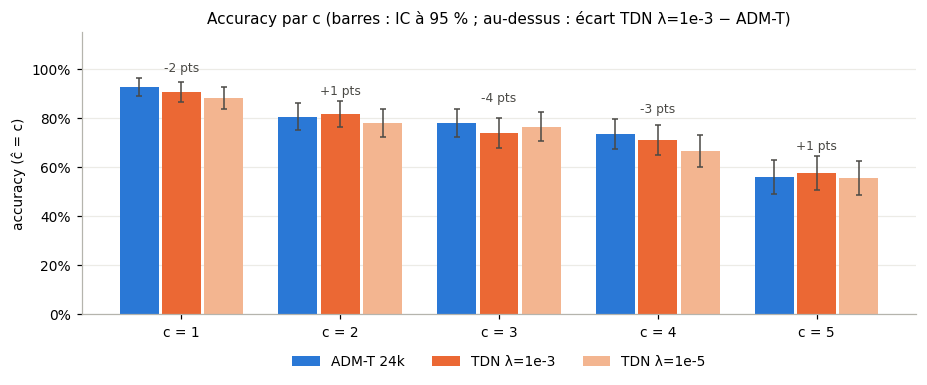

In [6]:
n_c = N_PER_C
table_c = pd.DataFrame({name: per_c[name].map(pct) for name in ALL})
for name in ALL[1:]:
    table_c[f"écart {name} − ADM-T"] = (per_c[name] - per_c[REF]).map(lambda x: pct(x, signed=True))
display(table_c.style.set_caption(f"Accuracy par c ({n_c} échantillons par c)"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(C_VALUES))
width = 0.8 / len(ALL)
for k, name in enumerate(ALL):
    acc = per_c[name].loc[list(C_VALUES)].to_numpy()
    half = 1.96 * np.sqrt(acc * (1 - acc) / n_c)
    pos = x + (k - (len(ALL) - 1) / 2) * width
    ax.bar(pos, acc, 0.92 * width, color=COLORS[name], label=name, zorder=2)
    ax.errorbar(pos, acc, yerr=half, fmt="none", ecolor="#4a4945", elinewidth=1, capsize=2, zorder=3)
for i, c in enumerate(C_VALUES):
    gap = per_c.loc[c, TDN] - per_c.loc[c, REF]
    acc = per_c.loc[c, ALL].to_numpy(dtype=float)
    top = np.max(acc + 1.96 * np.sqrt(acc * (1 - acc) / n_c))  # haut des barres d'erreur
    ax.text(i, top + 0.03, f"{100 * gap:+.0f} pts", ha="center", fontsize=8, color="#4a4945")
ax.set_xticks(x, [f"c = {c}" for c in C_VALUES])
ax.set_ylim(0, 1.15)
ax.set_yticks(np.linspace(0, 1, 6))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("accuracy (ĉ = c)")
ax.grid(axis="y", color="#ecebe6", zorder=0)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=len(ALL))
ax.set_title(f"Accuracy par c (barres : IC à 95 % ; au-dessus : écart {TDN} − ADM-T)")
plt.tight_layout()
plt.show()

## 4. Matrices de confusion
Ligne : nombre d'objets demandé c ; colonne : nombre compté ĉ. Chaque ligne est en pourcentage des échantillons demandés avec ce c ; la diagonale (encadrée) correspond aux échantillons justes. À droite, la différence TDN − ADM-T : en rouge ce que TDN produit plus souvent, en bleu moins souvent.

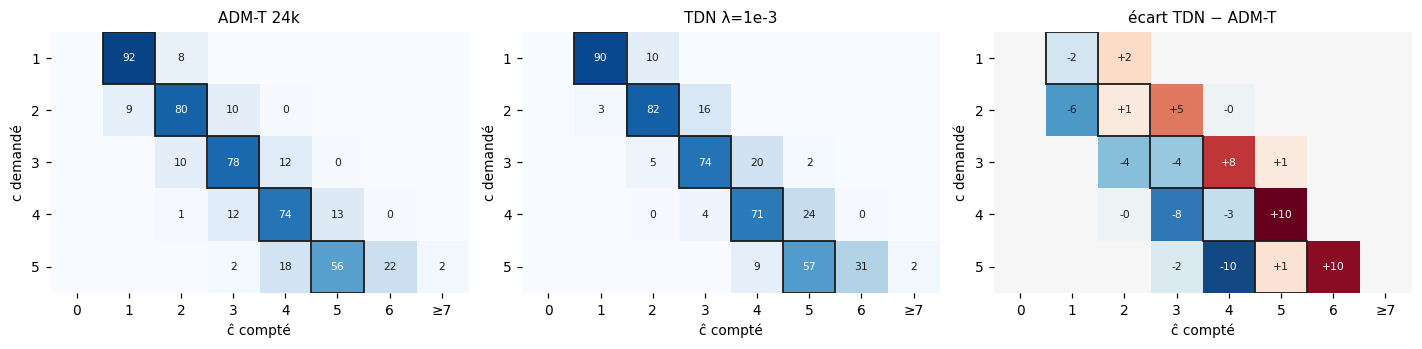

In [7]:
max_shown = max(C_VALUES) + 2  # dernière colonne : « ≥ 7 »
cols = list(range(0, max_shown + 1))
col_labels = [str(k) for k in cols[:-1]] + [f"≥{max_shown}"]


def confusion(name):
    pred = np.minimum(samples[name]["pred"], max_shown)
    m = np.array([[np.mean(pred[c_all == c] == k) for k in cols] for c in C_VALUES])
    return m


conf = {name: confusion(name) for name in NAMES}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes[:2], NAMES):
    ax.imshow(conf[name], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(name)
for ax, m, kind in [(axes[0], conf[REF], "seq"), (axes[1], conf[TDN], "seq"), (axes[2], conf[TDN] - conf[REF], "div")]:
    if kind == "div":
        v = max(np.abs(m).max(), 0.05)
        ax.imshow(m, cmap="RdBu_r", vmin=-v, vmax=v)
        ax.set_title("écart TDN − ADM-T")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            if abs(m[i, j]) >= 0.005:
                txt = f"{100 * m[i, j]:+.0f}" if kind == "div" else f"{100 * m[i, j]:.0f}"
                dark = m[i, j] > 0.55 if kind == "seq" else abs(m[i, j]) > 0.6 * v
                ax.text(j, i, txt, ha="center", va="center", fontsize=7, color="white" if dark else "#1f1e1c")
    for i, c in enumerate(C_VALUES):  # diagonale ĉ = c
        ax.add_patch(plt.Rectangle((c - 0.5, i - 0.5), 1, 1, fill=False, ec="#1f1e1c", lw=1.2))
    ax.set_xticks(range(len(cols)), col_labels)
    ax.set_yticks(range(len(C_VALUES)), list(C_VALUES))
    ax.set_xlabel("ĉ compté")
    ax.set_ylabel("c demandé")
    for side in ax.spines.values():
        side.set_visible(False)
plt.tight_layout()
plt.show()

## 5. Comparaison appariée
Même bruit initial pour les deux modèles : on peut donc regarder, échantillon par échantillon, ce que L_top change. *Corrigés* : faux pour ADM-T, justes pour TDN ; *cassés* : l'inverse.

In [8]:
pairs = pd.DataFrame(
    [[np.sum(ok[REF] & ok[TDN]), np.sum(ok[REF] & ~ok[TDN])],
     [np.sum(~ok[REF] & ok[TDN]), np.sum(~ok[REF] & ~ok[TDN])]],
    index=[f"{REF} juste", f"{REF} faux"],
    columns=["TDN juste", "TDN faux"],
)
display(pairs.style.format(lambda v: f"{v}  ({100 * v / n_total:.0f} %)").set_caption("Tous les c"))

rows = {}
for c in C_VALUES:
    m = c_all == c
    fixed = int(np.sum(m & ~ok[REF] & ok[TDN]))
    broken = int(np.sum(m & ok[REF] & ~ok[TDN]))
    rows[c] = {"corrigés par TDN": fixed, "cassés par TDN": broken, "bilan": f"{fixed - broken:+d}"}
by_c = pd.DataFrame(rows).T
by_c.index.name = "c"
display(by_c.style.set_caption(f"Par c ({N_PER_C} échantillons par c)"))

,TDN juste,TDN faux
ADM-T 24k juste,618 (62 %),143 (14 %)
ADM-T 24k faux,131 (13 %),108 (11 %)


,corrigés par TDN,cassés par TDN,bilan
c,,,
1,6,10,-4
2,24,22,+2
3,26,34,-8
4,29,34,-5
5,46,43,+3


## 6. Exemples
Chaque composante connexe a sa couleur : c'est exactement ce que compte la métrique. Titre : ĉ, en vert avec ✓ si ĉ = c, en rouge avec ✗ sinon.

### 6.1 Les quatre cas possibles
Pour chaque cas, des paires tirées au hasard : même bruit initial, ADM-T en haut, TDN en bas.

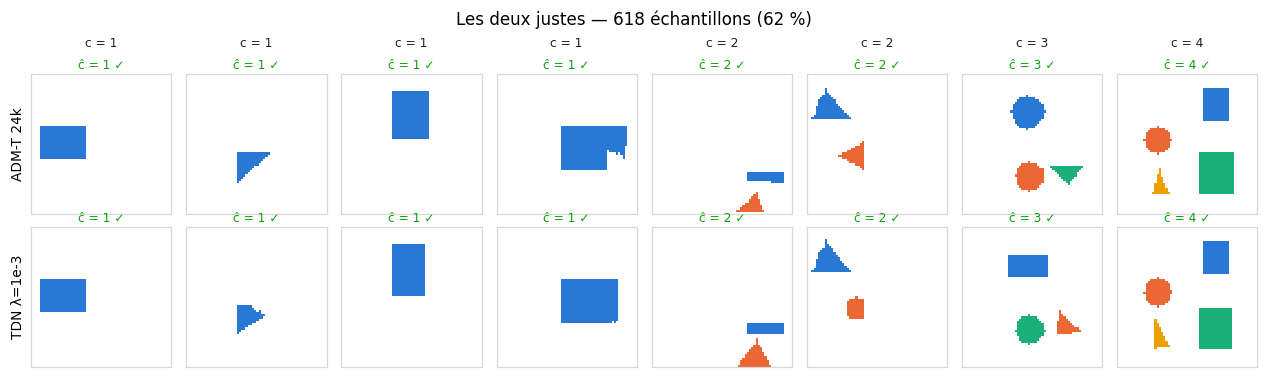

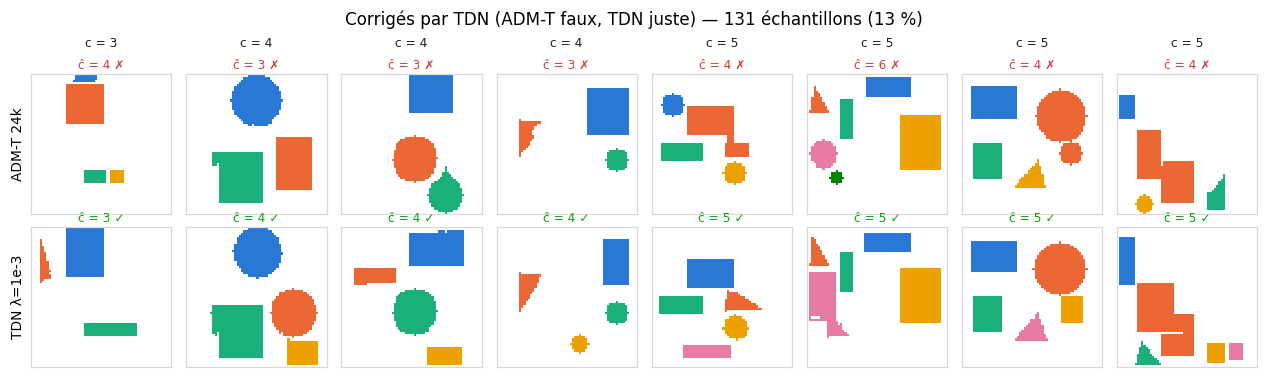

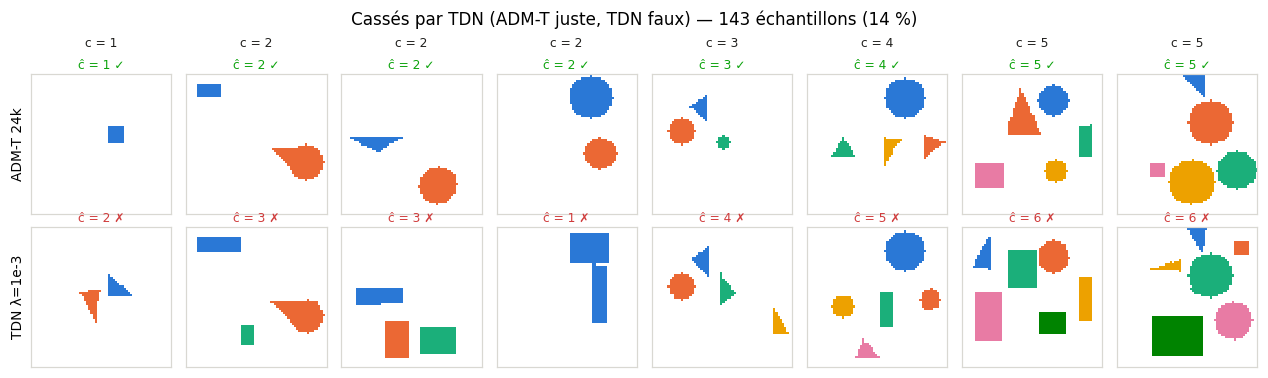

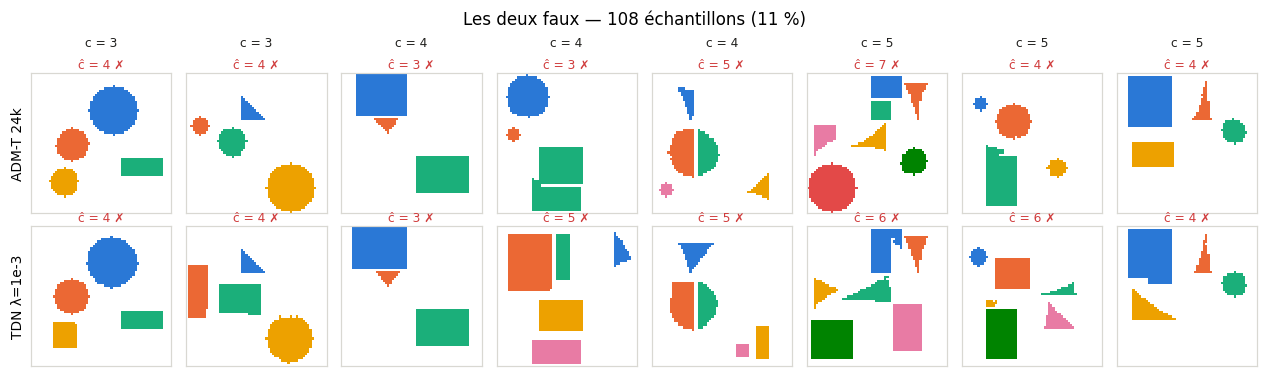

In [9]:
CASES = {
    "Les deux justes": ok[REF] & ok[TDN],
    "Corrigés par TDN (ADM-T faux, TDN juste)": ~ok[REF] & ok[TDN],
    "Cassés par TDN (ADM-T juste, TDN faux)": ok[REF] & ~ok[TDN],
    "Les deux faux": ~ok[REF] & ~ok[TDN],
}
N_SHOW = 8
rng = np.random.default_rng(0)
for case, mask in CASES.items():
    idx = np.flatnonzero(mask)
    if not len(idx):
        print(f"{case} : aucun échantillon")
        continue
    shown = np.sort(rng.choice(idx, size=min(N_SHOW, len(idx)), replace=False))
    fig, axes = plt.subplots(2, N_SHOW, figsize=(1.45 * N_SHOW, 3.5), squeeze=False)
    for col in range(N_SHOW):
        for row, name in enumerate(NAMES):
            ax = axes[row, col]
            if col >= len(shown):
                ax.axis("off")
                continue
            i = shown[col]
            show_mask(ax, samples[name]["images"][i, 0], c_all[i], f"c = {c_all[i]}" if row == 0 else "")
            if col == 0:
                ax.set_ylabel(name, fontsize=9)
    fig.suptitle(f"{case} — {len(idx)} échantillons ({100 * len(idx) / n_total:.0f} %)", fontsize=11)
    plt.tight_layout()
    plt.show()

### 6.2 Mêmes bruits, pour chaque c
Les 4 premiers bruits initiaux de chaque c (non choisis), ADM-T à gauche et TDN à droite de chaque paire.

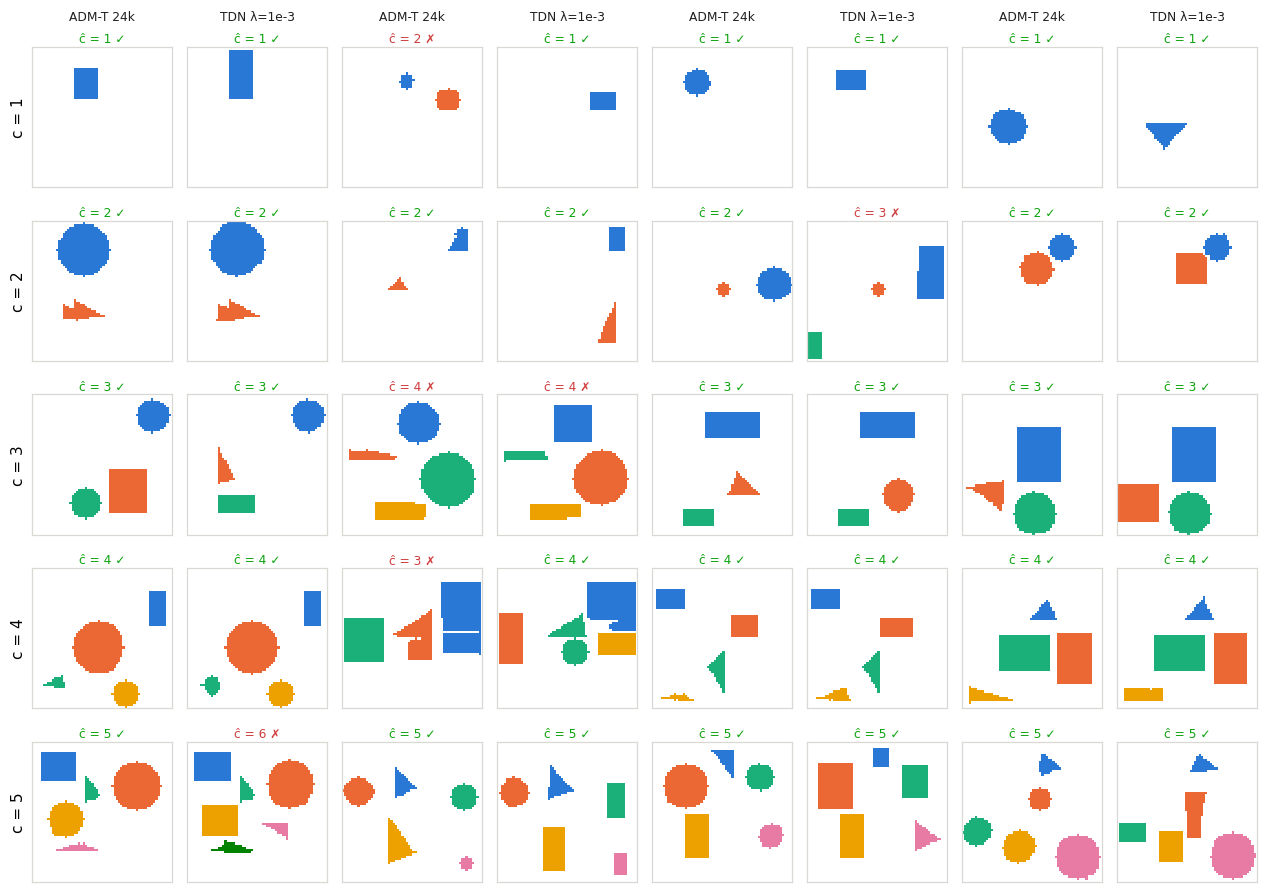

In [10]:
K = 4
fig, axes = plt.subplots(len(C_VALUES), 2 * K, figsize=(1.45 * 2 * K, 1.65 * len(C_VALUES)), squeeze=False)
for row, c in enumerate(C_VALUES):
    for k, i in enumerate(np.flatnonzero(c_all == c)[:K]):
        for m, name in enumerate(NAMES):
            ax = axes[row, 2 * k + m]
            show_mask(ax, samples[name]["images"][i, 0], c, name if row == 0 else "")
            if k == 0 and m == 0:
                ax.set_ylabel(f"c = {c}", fontsize=10)
plt.tight_layout()
plt.show()

## 7. Types d'erreurs
Une erreur est soit un **sur-comptage** (ĉ > c : fragment parasite, objet coupé en deux), soit un **sous-comptage** (ĉ < c : objets fusionnés ou manquants). Tableau : répartition de ĉ − c pour les trois modèles ; figures : exemples de chaque type pour chaque modèle.

ĉ − c,≤ −3,−2,−1,0 (juste),+1,+2,≥ +3
ADM-T 24k,0.0 %,0.5 %,9.8 %,76.1 %,12.8 %,0.8 %,0.0 %
TDN λ=1e-3,0.0 %,0.1 %,4.3 %,74.9 %,19.8 %,0.9 %,0.0 %
TDN λ=1e-5,0.0 %,0.3 %,6.5 %,72.9 %,19.4 %,0.9 %,0.0 %


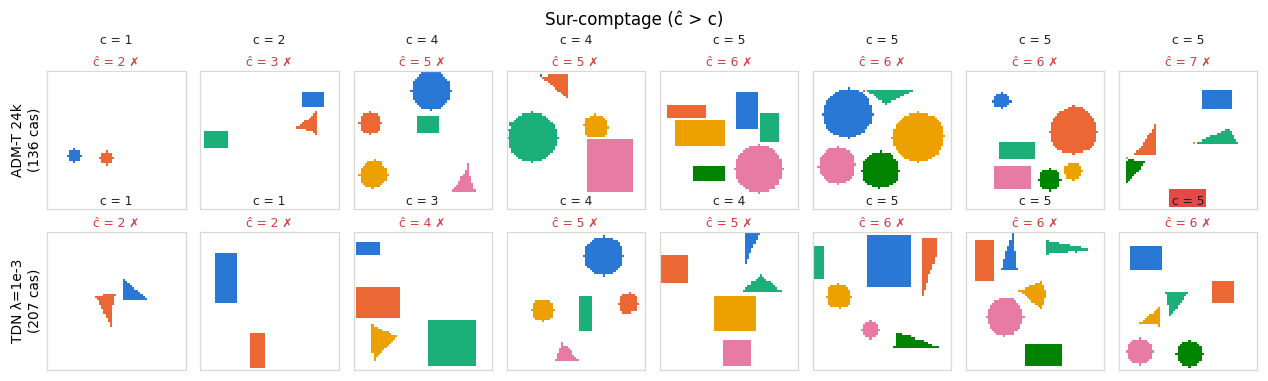

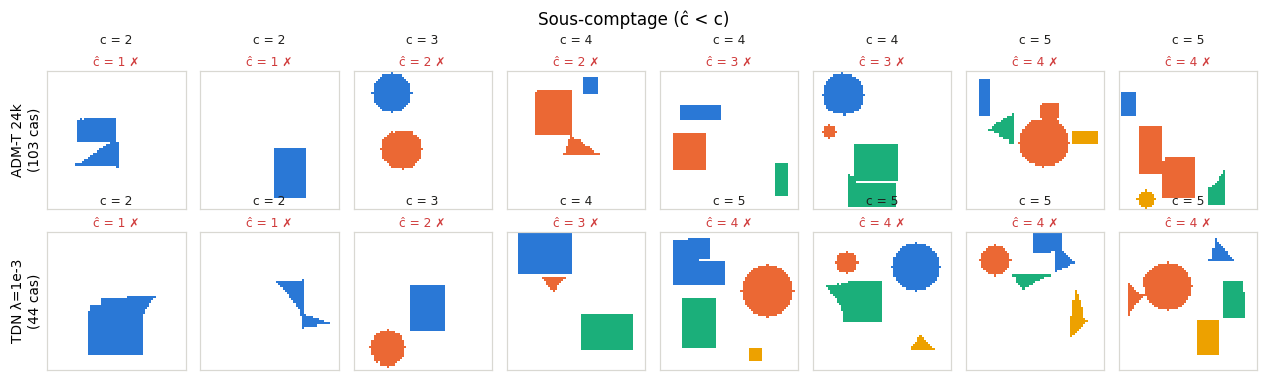

In [11]:
err = {name: np.clip(samples[name]["pred"] - c_all, -3, 3) for name in ALL}
labels = {-3: "≤ −3", 3: "≥ +3"}
dist = pd.DataFrame({
    name: pd.Series(err[name]).value_counts(normalize=True).reindex(range(-3, 4), fill_value=0)
    for name in ALL
})
dist.index = [labels.get(k, f"{k:+d}".replace("-", "−") if k else "0 (juste)") for k in dist.index]
dist.index.name = "ĉ − c"
display(dist.T.style.format(lambda v: f"{100 * v:.1f} %").set_caption("Répartition de l'erreur de comptage"))

N_ERR = 8
rng = np.random.default_rng(1)
for kind, sel in [("Sur-comptage (ĉ > c)", lambda e: e > 0), ("Sous-comptage (ĉ < c)", lambda e: e < 0)]:
    fig, axes = plt.subplots(2, N_ERR, figsize=(1.45 * N_ERR, 3.5), squeeze=False)
    for row, name in enumerate(NAMES):
        idx = np.flatnonzero(sel(samples[name]["pred"] - c_all))
        shown = np.sort(rng.choice(idx, size=min(N_ERR, len(idx)), replace=False)) if len(idx) else []
        for col in range(N_ERR):
            ax = axes[row, col]
            if col >= len(shown):
                ax.axis("off")
                continue
            i = shown[col]
            show_mask(ax, samples[name]["images"][i, 0], c_all[i], f"c = {c_all[i]}")
            if col == 0:
                ax.set_ylabel(f"{name}\n({len(idx)} cas)", fontsize=9)
    fig.suptitle(kind, fontsize=11)
    plt.tight_layout()
    plt.show()

## 8. x̂₀ au fil du débruitage
Équivalent de la figure 8 de l'article. À chaque pas DDIM, le modèle prédit l'image finale x̂₀ ; on regarde à partir de quel pas son nombre de composantes est fixé, avec les mêmes bruits initiaux pour les deux modèles.

C'est ce qui justifie d'appliquer L_top seulement pour t < 500 : si le nombre d'objets se décide tôt (t grand), x̂₀ y est encore flou.

Les trajectoires (32 par c sur GPU, 8 sur CPU) sont sauvegardées dans `samples/<modèle>/trajectory.npz` et ne sont pas régénérées si ce fichier existe.

In [12]:
N_TRAJ = 32 if DEVICE == "cuda" else 8  # trajectoires par valeur de c

traj = {}  # nom -> c -> x̂₀ des 4 premières trajectoires (4, NUM_STEPS, 1, 64, 64)
traj_counts = {}  # nom -> c -> nombre de composantes de x̂₀ (N_TRAJ, NUM_STEPS)
for name in NAMES:
    ckpt, out = MODELS[name]
    traj[name], traj_counts[name], timesteps = cached_trajectories(
        name, ckpt, out, N_TRAJ, DEVICE, num_steps=NUM_STEPS, threshold=THRESHOLD, force=FORCE_REGEN
    )

ADM-T 24k : trajectoires existantes (samples/admt_24k/trajectory.npz)
TDN λ=1e-3 : c = 1 fait
TDN λ=1e-3 : c = 2 fait
TDN λ=1e-3 : c = 3 fait
TDN λ=1e-3 : c = 4 fait
TDN λ=1e-3 : c = 5 fait
TDN λ=1e-3 : trajectoires sauvegardées dans samples/tdn_lam1e-3/trajectory.npz


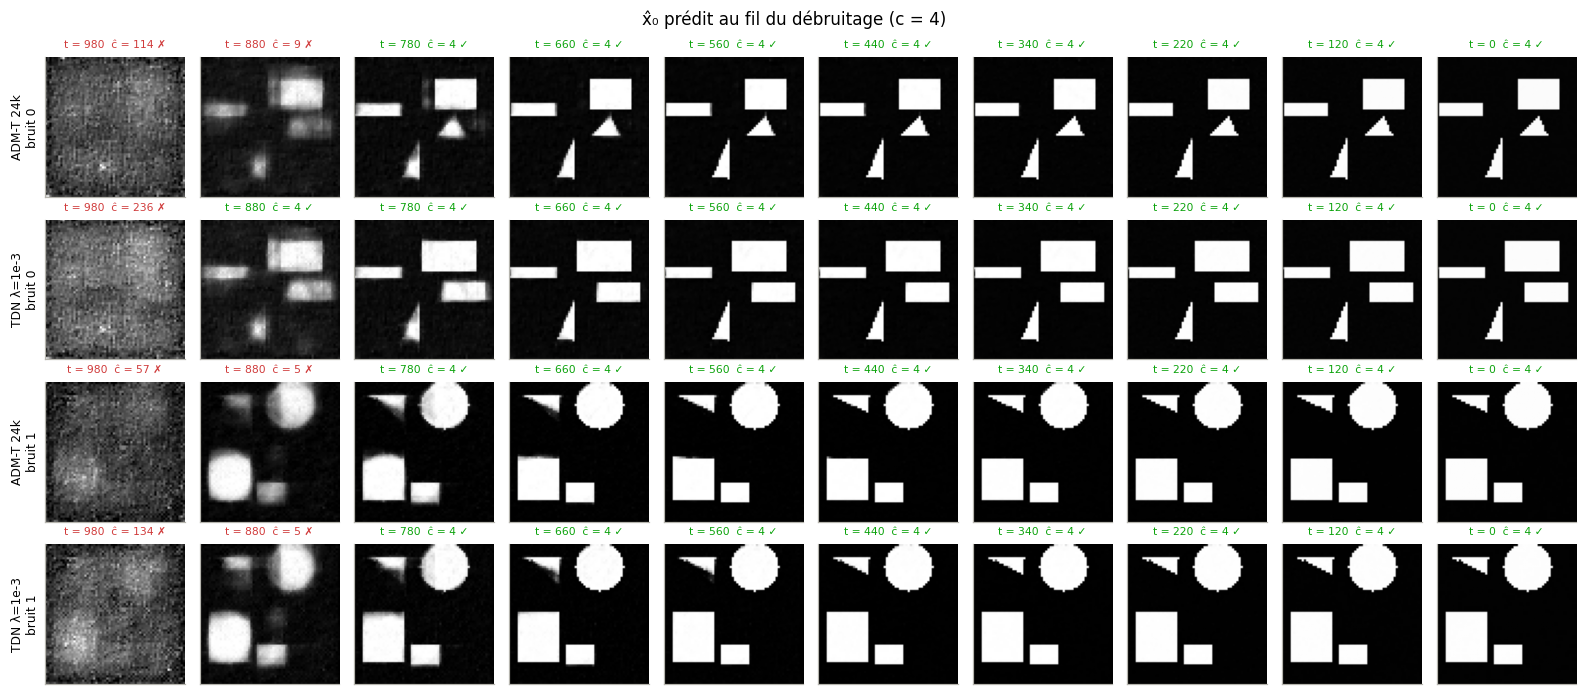

In [13]:
# Un exemple par modèle (même bruit initial) : x̂₀ à 10 pas de temps, c = 4
C_SHOW = 4
EXAMPLES = [0, 1]
cols_idx = np.linspace(0, NUM_STEPS - 1, 10).astype(int)
rows = [(name, i) for i in EXAMPLES for name in NAMES]
fig, axes = plt.subplots(len(rows), len(cols_idx), figsize=(1.45 * len(cols_idx), 1.6 * len(rows)), squeeze=False)
for r, (name, i) in enumerate(rows):
    for col, s in enumerate(cols_idx):
        ax = axes[r, col]
        x0 = traj[name][C_SHOW][i, s, 0]
        n = ndimage.label(x0 > THRESHOLD)[1]
        ax.imshow(x0, cmap="gray", vmin=-1, vmax=1)
        ax.set_title(f"t = {timesteps[s]}  ĉ = {n} {'✓' if n == C_SHOW else '✗'}", fontsize=7,
                     color=GOOD if n == C_SHOW else BAD)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(f"{name}\nbruit {i}", fontsize=8)
fig.suptitle(f"x̂₀ prédit au fil du débruitage (c = {C_SHOW})", fontsize=11)
plt.tight_layout()
plt.show()

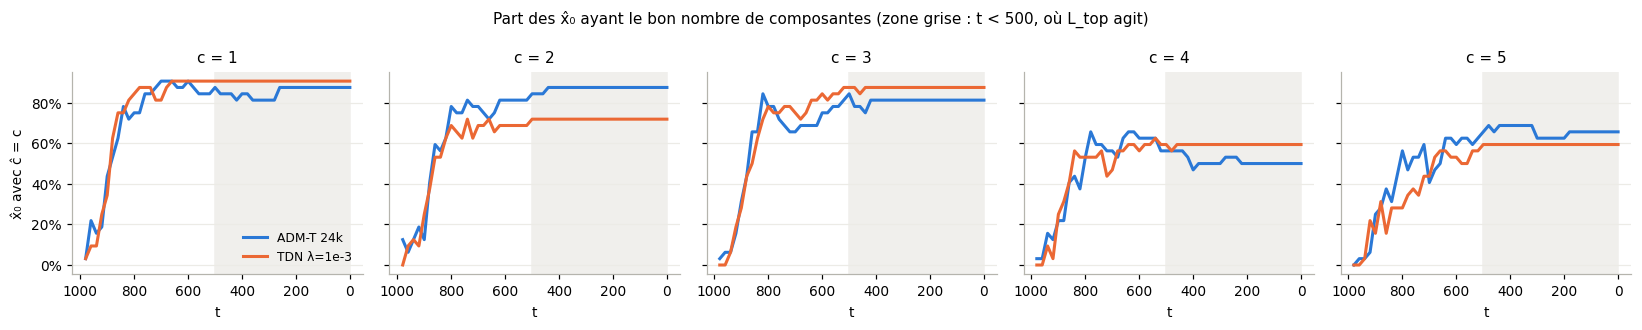

In [14]:
# Proportion des x̂₀ ayant exactement c composantes, en fonction de t (le débruitage va de gauche à droite)
fig, axes = plt.subplots(1, len(C_VALUES), figsize=(3 * len(C_VALUES), 3), sharey=True)
for ax, c in zip(axes, C_VALUES):
    for name in NAMES:
        acc_t = np.mean(traj_counts[name][c] == c, axis=0)
        ax.plot(timesteps, acc_t, color=COLORS[name], lw=2, label=name)
    ax.axvspan(0, 500, color="#f0efec", zorder=0)  # zone où L_top agit
    ax.invert_xaxis()
    ax.set_xlabel("t")
    ax.set_title(f"c = {c}")
    ax.grid(axis="y", color="#ecebe6")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_ylabel("x̂₀ avec ĉ = c")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Part des x̂₀ ayant le bon nombre de composantes (zone grise : t < 500, où L_top agit)", fontsize=10)
plt.tight_layout()
plt.show()